# MNIST: Autoencoder and PCA — How much does latent dimension matter?

**Goal:** Compare reconstruction as the latent dimension increases through
**2, 4, 8, 16, 32, and 64**.

We retain the uploaded notebook's autoencoder architecture:
$784\to512\to d\to512\to784$, with ReLU hidden activations and a sigmoid output.
Only the bottleneck width $d$ changes. For each $d$, we train a fresh autoencoder and compare
it with a $d$-component PCA reconstruction of the same images.

Once fitted, both methods encode and reconstruct an input deterministically. This notebook
focuses on **compression and reconstruction of observed images**. There are no random-image
sampling, decoded-grid, or interpolation sections. Digit labels are used only to annotate
plots and select example images, never as training targets.

**Run all cells in order.** The default `QUICK_RUN = False` uses 55,000 training images and
**50 epochs** per autoencoder, with a separate validation split. Set `QUICK_RUN = True`
for a shorter demonstration using 10,000 training images and 10 epochs per autoencoder;
the shorter run should not be treated as a converged benchmark.
Every dimension uses the same data, epoch budget, optimizer, learning rate, and batch size.

The notebook includes an error-versus-dimension plot, matched reconstruction panels, PCA explained
variance, autoencoder learning curves, and a two-dimensional embedding comparison.


## 0. Setup and data

Uncomment the installation command if an import fails. A GPU is optional; CPU, CUDA,
and Apple MPS are supported. The first run needs internet access to download MNIST.


In [1]:
# Uncomment if needed:
# %pip install torch torchvision scikit-learn matplotlib pandas


In [2]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from IPython.display import display

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.decomposition import PCA


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


SEED = 42
seed_everything(SEED)
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
print('PyTorch:', torch.__version__)
print('Device:', device)
# The seed improves repeatability; different hardware can still give different results.


PyTorch: 2.7.0
Device: mps


In [4]:
# Change these settings, then rerun all subsequent cells.
QUICK_RUN = False
LATENT_DIMS = [2, 4, 8, 16, 32, 64]
HIDDEN_DIM = 512
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 10 if QUICK_RUN else 50
TRAIN_LIMIT = 10_000 if QUICK_RUN else None
VAL_SIZE = 5_000
NUM_WORKERS = 0         # Portable in notebooks, Colab, and Windows.
DATA_DIR = Path('./data')

assert LATENT_DIMS == sorted(set(LATENT_DIMS)), 'Use distinct dimensions in increasing order.'
assert all(isinstance(d, int) and 1 <= d < 784 for d in LATENT_DIMS)


### Fix the data before varying the dimension

Split the original MNIST training data into **55,000 training** and **5,000 validation** images.
Quick mode retains the same fixed random subset of 10,000 training images for every fit.
The official **10,000 test images** are held out from fitting.

`ToTensor()` gives images of shape `(1, 28, 28)` with pixel intensities in $[0,1]$.
PCA receives the same pixel values, flattened into 784-dimensional vectors. We do not binarize
or standardize the pixels. Validation curves diagnose training; we compare the final epoch
for every dimension, without selecting weights or dimensions using the test set.


In [5]:
mnist_train = datasets.MNIST(DATA_DIR, train=True, download=True,
                             transform=transforms.ToTensor())
mnist_test = datasets.MNIST(DATA_DIR, train=False, download=True,
                            transform=transforms.ToTensor())

split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(mnist_train), generator=split_generator)
val_indices = permutation[:VAL_SIZE].tolist()
train_indices = permutation[VAL_SIZE:].tolist()
if TRAIN_LIMIT is not None:
    train_indices = train_indices[:TRAIN_LIMIT]

train_data = Subset(mnist_train, train_indices)
val_data = Subset(mnist_train, val_indices)
test_data = mnist_test


def make_train_loader():
    # Each dimension sees the same shuffle sequence when fitted from scratch.
    return DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED),
                      num_workers=NUM_WORKERS, pin_memory=(device.type == 'cuda'))


val_loader = DataLoader(val_data, batch_size=512, shuffle=False,
                        num_workers=NUM_WORKERS)
test_loader = DataLoader(test_data, batch_size=512, shuffle=False,
                         num_workers=NUM_WORKERS)

print(f'Train: {len(train_data):,}; validation: {len(val_data):,}; test: {len(test_data):,}')
images, labels = next(iter(make_train_loader()))
print('Image batch:', tuple(images.shape), '| label batch:', tuple(labels.shape))
print('Pixel range:', images.min().item(), images.max().item())


train_eval_loader = DataLoader(train_data, batch_size=512, shuffle=False,
                               num_workers=NUM_WORKERS)
RUN_LABEL = f'{len(train_data):,} training images; {EPOCHS} epochs per AE'
print(RUN_LABEL)


Train: 55,000; validation: 5,000; test: 10,000
Image batch: (128, 1, 28, 28) | label batch: (128,)
Pixel range: 0.0 1.0
55,000 training images; 50 epochs per AE


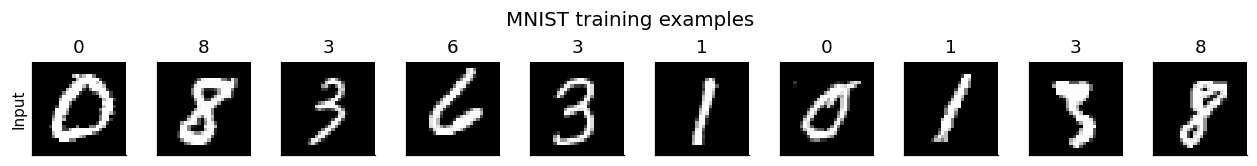

In [6]:
def image_rows(rows, row_names, column_titles=None, heading=None):
    """Each row is an array/tensor of N images. All panels use intensity range [0, 1]."""
    n = len(rows[0])
    fig, axes = plt.subplots(len(rows), n, figsize=(1.15 * n, 1.4 * len(rows)),
                             squeeze=False, layout='constrained')
    for r, (row, name) in enumerate(zip(rows, row_names)):
        if torch.is_tensor(row):
            row = row.detach().cpu().numpy()
        for c in range(n):
            axes[r, c].imshow(np.asarray(row[c]).reshape(28, 28), cmap='gray',
                              vmin=0, vmax=1)
            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])
            if r == 0 and column_titles is not None:
                axes[r, c].set_title(str(column_titles[c]))
        axes[r, 0].set_ylabel(name, fontsize=10)
    if heading:
        fig.suptitle(heading, fontsize=13)
    plt.show()


image_rows([images[:10]], ['Input'], labels[:10].tolist(), 'MNIST training examples')


## 1. Autoencoder (AE)

The encoder and decoder are learned together:

$$x\in\mathbb R^{784}\ \xrightarrow{\ e_\phi\ }\ z\in\mathbb R^d
\ \xrightarrow{\ f_\theta\ }\ \hat x\in[0,1]^{784}.$$

For a minibatch of $B$ images we minimize

$$\mathcal L_{\rm AE}=\frac1B\sum_{i=1}^{B}\sum_{j=1}^{784}
(x_{ij}-\hat x_{ij})^2.$$

We **sum over pixels, then average over images**. This is 784 times the mean per-pixel squared
error reported in the comparison table. The encoder has no constraint requiring its latent
coordinates to follow a normal distribution.

The architecture is $784\to512\to d$ for the encoder and $d\to512\to784$ for the decoder.
ReLU supplies nonlinearity; the decoder's sigmoid keeps its output mean in $[0,1]$.


We use this same class for every $d$; the hidden width remains 512. Changing $d$ necessarily
changes the sizes of the two layers adjacent to the bottleneck, and therefore the parameter count.
Training uses random initialization and shuffled minibatches, but a fitted model's reconstruction
$\hat x=f_\theta(e_\phi(x))$ is deterministic.


In [8]:
class Encoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 784),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.net(z).reshape(-1, 1, 28, 28)


class Autoencoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim=512):
        super().__init__()
        self.encoder = Encoder(latent_dim, hidden_dim)
        self.decoder = Decoder(latent_dim, hidden_dim)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def sse_per_image(x_hat, x):
    # (B, 1, 28, 28) -> (B, 784) -> (B,)
    return (x_hat - x).square().flatten(start_dim=1).sum(dim=1)


@torch.inference_mode()
def evaluate_ae(model, loader):
    model.eval()
    total_sse = 0.0
    for x, _ in loader:
        x = x.to(device)
        total_sse += sse_per_image(model(x), x).sum().item()
    return total_sse / (len(loader.dataset) * 784)


### Train one independent autoencoder for each dimension

Each run resets the random seed, constructs a fresh model, and starts a new optimizer. No weights
are transferred between dimensions. The same loader seed fixes the minibatch ordering.

`model.train()` starts each epoch; `evaluate_ae()` switches to evaluation mode and uses
`torch.inference_mode()`. The training curve averages errors during weight updates, while
validation is evaluated at the end of the epoch. The final comparison evaluates the final model
on each complete split.


In [9]:
def train_ae(model, loader, epochs, latent_dim):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        total_sse = 0.0
        for x, _ in loader:
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            x_hat = model(x)
            per_image = sse_per_image(x_hat, x)
            loss = per_image.mean()
            loss.backward()
            optimizer.step()
            total_sse += per_image.detach().sum().item()
        train_mse = total_sse / (len(loader.dataset) * 784)
        val_mse = evaluate_ae(model, val_loader)
        history.append({'epoch': epoch, 'train_mse': train_mse, 'val_mse': val_mse})
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f'd={latent_dim:2d} | epoch {epoch:02d}/{epochs}'
                  f' | train MSE {train_mse:.5f} | val MSE {val_mse:.5f}', flush=True)
    return pd.DataFrame(history), time.perf_counter() - start


In [10]:
ae_models = {}
ae_histories = {}
ae_times = {}
for d in LATENT_DIMS:
    seed_everything(SEED)
    model = Autoencoder(d, HIDDEN_DIM).to(device)
    print(f'\nTraining AE with d={d} ({sum(p.numel() for p in model.parameters()):,} parameters)',
          flush=True)
    history, seconds = train_ae(model, make_train_loader(), EPOCHS, d)
    ae_models[d] = model.cpu()  # Retain each fit without keeping all models on the GPU.
    ae_histories[d] = history
    ae_times[d] = seconds
print('All autoencoders finished.')



Training AE with d=2 (806,674 parameters)
d= 2 | epoch 01/50 | train MSE 0.05605 | val MSE 0.04971
d= 2 | epoch 05/50 | train MSE 0.04439 | val MSE 0.04463
d= 2 | epoch 10/50 | train MSE 0.04217 | val MSE 0.04281
d= 2 | epoch 15/50 | train MSE 0.04104 | val MSE 0.04206
d= 2 | epoch 20/50 | train MSE 0.04021 | val MSE 0.04150
d= 2 | epoch 25/50 | train MSE 0.03961 | val MSE 0.04130
d= 2 | epoch 30/50 | train MSE 0.03909 | val MSE 0.04096
d= 2 | epoch 35/50 | train MSE 0.03871 | val MSE 0.04078
d= 2 | epoch 40/50 | train MSE 0.03838 | val MSE 0.04072
d= 2 | epoch 45/50 | train MSE 0.03811 | val MSE 0.04063
d= 2 | epoch 50/50 | train MSE 0.03785 | val MSE 0.04052

Training AE with d=4 (808,724 parameters)
d= 4 | epoch 01/50 | train MSE 0.04662 | val MSE 0.03692
d= 4 | epoch 05/50 | train MSE 0.03206 | val MSE 0.03217
d= 4 | epoch 10/50 | train MSE 0.03008 | val MSE 0.03066
d= 4 | epoch 15/50 | train MSE 0.02908 | val MSE 0.02988
d= 4 | epoch 20/50 | train MSE 0.02841 | val MSE 0.02940
d=

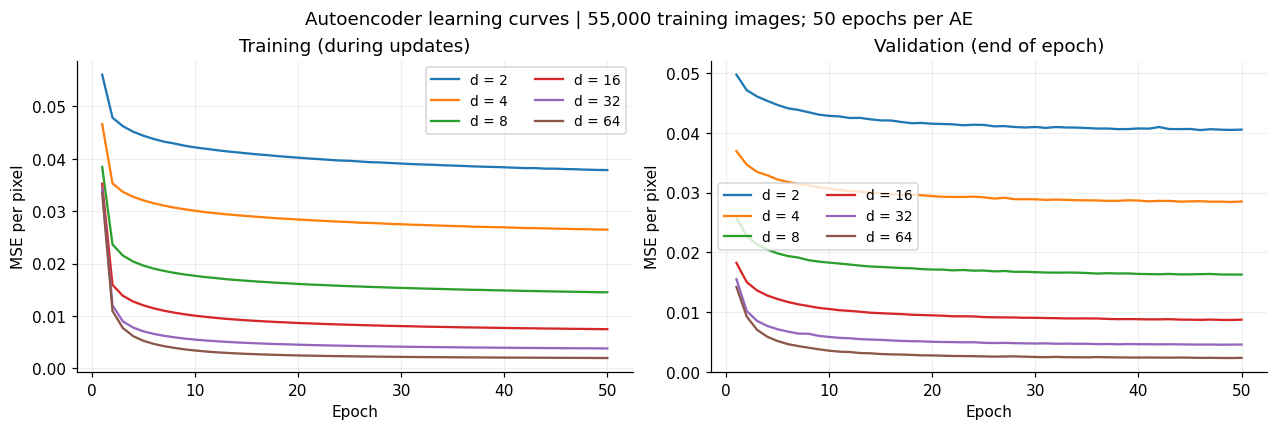

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), layout='constrained')
for d in LATENT_DIMS:
    h = ae_histories[d]
    axes[0].plot(h.epoch, h.train_mse, label=f'd = {d}')
    axes[1].plot(h.epoch, h.val_mse, label=f'd = {d}')
for ax, title in zip(axes, ['Training (during updates)', 'Validation (end of epoch)']):
    ax.set(xlabel='Epoch', ylabel='MSE per pixel', title=title)
    ax.grid(alpha=0.2)
    ax.legend(ncol=2, fontsize=9)
fig.suptitle('Autoencoder learning curves | ' + RUN_LABEL)
plt.show()


## 2. PCA at the same latent dimensions

Let $X\in\mathbb R^{n\times784}$ contain one image per row, and let $\bar x$ be the training
mean. With $X_c=X-\mathbf1\bar x^\top$, PCA chooses orthonormal columns
$W_d\in\mathbb R^{784\times d}$ to minimize

$$\|X_c-X_cW_dW_d^\top\|_F^2,\qquad W_d^\top W_d=I_d.$$

For any image, encoding and reconstruction are

$$z=(x-\bar x)^\top W_d,\qquad \hat x^\top=zW_d^\top+\bar x^\top.$$

PCA is linear; the autoencoder above is nonlinear. PCA does not require Gaussian data.
An unconstrained linear autoencoder with squared-error loss can recover the PCA subspace at a
global optimum, but the nonlinear autoencoder here is a different model.

**Fit once, retain different numbers of components.** We fit PCA on the training data with
`max(LATENT_DIMS)` components and use the first $d$ columns for each comparison. These are nested
subspaces of the same PCA fit. Because adding an orthogonal direction cannot increase projection
error, raw PCA reconstruction error cannot increase as $d$ grows, for training or held-out images
(apart from numerical rounding). An independently trained neural model need not show the same
monotonic pattern after a finite number of optimization steps.


In [13]:
# These pixel values match ToTensor(): uint8 / 255.
X_train = mnist_train.data[train_indices].numpy().reshape(-1, 784).astype(np.float32) / 255.0
X_val = mnist_train.data[val_indices].numpy().reshape(-1, 784).astype(np.float32) / 255.0
X_test = mnist_test.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
y_test = mnist_test.targets.numpy()

assert max(LATENT_DIMS) <= min(X_train.shape)
start = time.perf_counter()
pca = PCA(n_components=max(LATENT_DIMS), svd_solver='full')
pca.fit(X_train)
pca_fit_seconds = time.perf_counter() - start


def pca_encode(X, d):
    # sklearn stores each loading vector as a row.
    return (X - pca.mean_) @ pca.components_[:d].T


def pca_reconstruct(X, d):
    return pca_encode(X, d) @ pca.components_[:d] + pca.mean_


def mse_per_pixel(X, X_hat):
    # Float64 accumulation avoids unnecessary rounding in a large sum.
    return float(np.mean((X - X_hat) ** 2, dtype=np.float64))


print(f'PCA fit: {pca_fit_seconds:.2f} seconds, shared by every retained dimension.')
print(f'Maximum retained components: {pca.n_components_}')


PCA fit: 2.19 seconds, shared by every retained dimension.
Maximum retained components: 64


## 3. Quantitative comparison: dimension versus reconstruction error

The common metric for both methods is

$$\operatorname{MSE}=\frac{1}{n\,784}\sum_{i=1}^{n}\|x_i-\hat x_i\|^2.$$

Both methods use the same pixels, split, and $d$. PCA reconstruction values can lie outside
$[0,1]$; **we retain those raw values for MSE**. Image displays use a fixed $[0,1]$ intensity scale,
so out-of-range PCA values saturate visually. The AE output is bounded by its sigmoid.

We report train, validation, and test MSE. The full test curves are descriptive comparisons across
the prespecified dimensions; use validation, rather than repeated test inspection, to choose $d$
for a final predictive model. Neither equal dimension nor equal epoch budget makes this an
exhaustive comparison of the methods' best attainable performance.


In [14]:
records = []
for d in LATENT_DIMS:
    model = ae_models[d].to(device)
    ae_errors = {split: evaluate_ae(model, loader)
                 for split, loader in [('Train', train_eval_loader),
                                       ('Validation', val_loader), ('Test', test_loader)]}
    model.cpu()
    pca_errors = {split: mse_per_pixel(X, pca_reconstruct(X, d))
                  for split, X in [('Train', X_train), ('Validation', X_val), ('Test', X_test)]}
    records.append({'Latent dimension': d, 'Input / latent dimension': 784 / d,
                    'AE parameters': sum(p.numel() for p in model.parameters()),
                    **{f'AE {split} MSE': v for split, v in ae_errors.items()},
                    **{f'PCA {split} MSE': v for split, v in pca_errors.items()},
                    'PCA explained variance': float(pca.explained_variance_ratio_[:d].sum()),
                    'AE training seconds': ae_times[d]})

results = pd.DataFrame(records).set_index('Latent dimension')
print(RUN_LABEL)
display(results[['AE Train MSE', 'AE Validation MSE', 'AE Test MSE',
                 'PCA Train MSE', 'PCA Validation MSE', 'PCA Test MSE']].style.format('{:.5f}'))
display(results[['Input / latent dimension', 'AE parameters', 'PCA explained variance',
                 'AE training seconds']].style.format({
    'Input / latent dimension': '{:.2f}', 'AE parameters': '{:,.0f}',
    'PCA explained variance': '{:.1%}', 'AE training seconds': '{:.1f}'}))
print('Input / latent dimension compares coordinates per image; it excludes model storage.')
print('AE training times include validation after each epoch. PCA is fitted once above.')


55,000 training images; 50 epochs per AE


,AE Train MSE,AE Validation MSE,AE Test MSE,PCA Train MSE,PCA Validation MSE,PCA Test MSE
Latent dimension,,,,,,
2,0.03767,0.04052,0.04003,0.05595,0.05596,0.05567
4,0.02638,0.02850,0.02816,0.04817,0.04831,0.04790
8,0.01435,0.01629,0.01577,0.03785,0.03804,0.03744
16,0.00737,0.00874,0.00840,0.02727,0.02755,0.02686
32,0.00374,0.00458,0.00437,0.01723,0.01743,0.01683
64,0.00196,0.00237,0.00227,0.00928,0.00938,0.00905


,Input / latent dimension,AE parameters,PCA explained variance,AE training seconds
Latent dimension,,,,
2,392.00,"806,674",16.8%,113.6
4,196.00,"808,724",28.4%,112.5
8,98.00,"812,824",43.7%,126.0
16,49.00,"821,024",59.4%,114.2
32,24.50,"837,424",74.4%,116.2
64,12.25,"870,224",86.2%,122.6


Input / latent dimension compares coordinates per image; it excludes model storage.
AE training times include validation after each epoch. PCA is fitted once above.


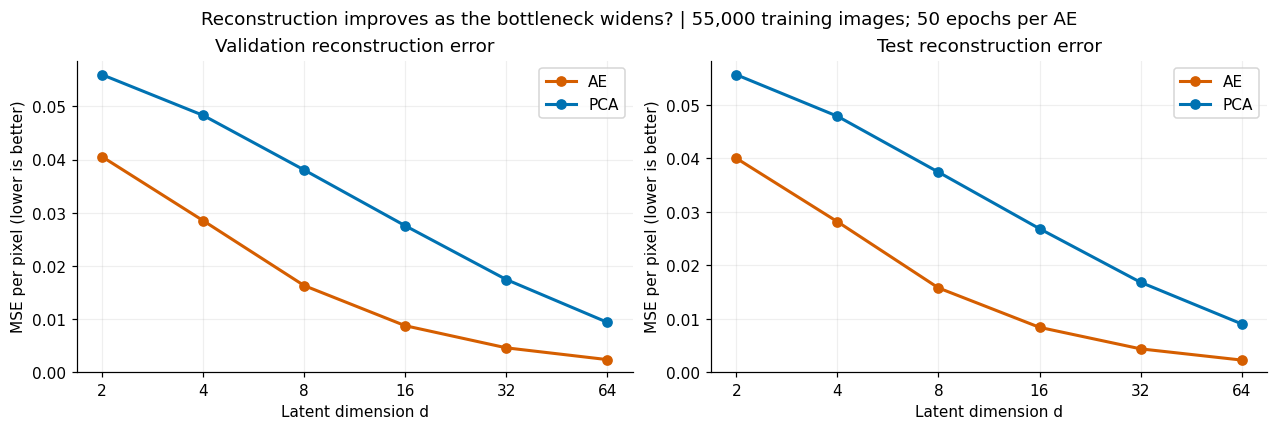

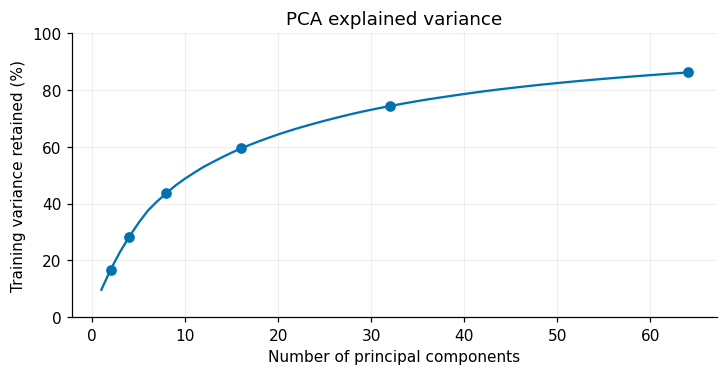

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), layout='constrained')
colors = {'AE': '#D55E00', 'PCA': '#0072B2'}
for ax, split in zip(axes, ['Validation', 'Test']):
    for method in ['AE', 'PCA']:
        ax.plot(LATENT_DIMS, results[f'{method} {split} MSE'], 'o-',
                color=colors[method], linewidth=2, label=method)
    ax.set_xscale('log', base=2)
    ax.set_xticks(LATENT_DIMS, labels=[str(d) for d in LATENT_DIMS])
    ax.set(xlabel='Latent dimension d', ylabel='MSE per pixel (lower is better)',
           title=f'{split} reconstruction error', ylim=(0, None))
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle('Reconstruction improves as the bottleneck widens? | ' + RUN_LABEL)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.3), layout='constrained')
ax.plot(np.arange(1, pca.n_components_ + 1), 100 * np.cumsum(pca.explained_variance_ratio_),
         color=colors['PCA'])
ax.scatter(LATENT_DIMS, 100 * results['PCA explained variance'], color=colors['PCA'])
ax.set(xlabel='Number of principal components', ylabel='Training variance retained (%)',
       title='PCA explained variance', ylim=(0, 100))
ax.grid(alpha=0.2)
plt.show()


## 4. See what changes in the same test digits

Select one fixed test image of each digit and use it for every reconstruction. Each figure shows
the original images followed by the reconstructions at all six latent dimensions. These examples
illustrate changes in shape and detail; the MSE table evaluates all 10,000 test images.

The plot range stays $[0,1]$ for every method and dimension, so contrast is not rescaled separately
to make one reconstruction look better. Inspect both plots and the numerical error curve.


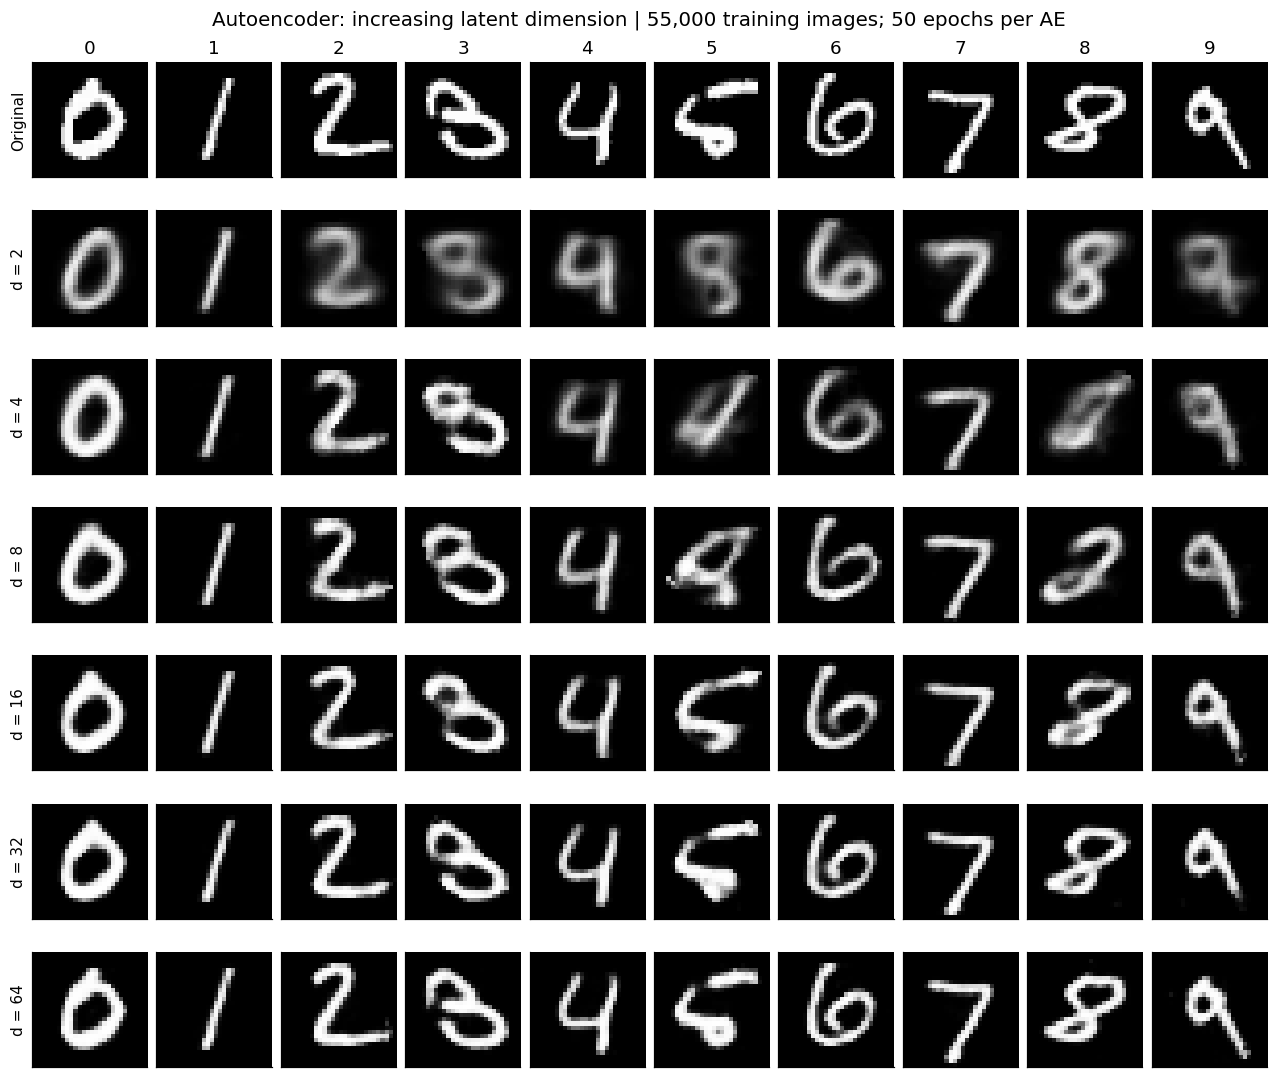

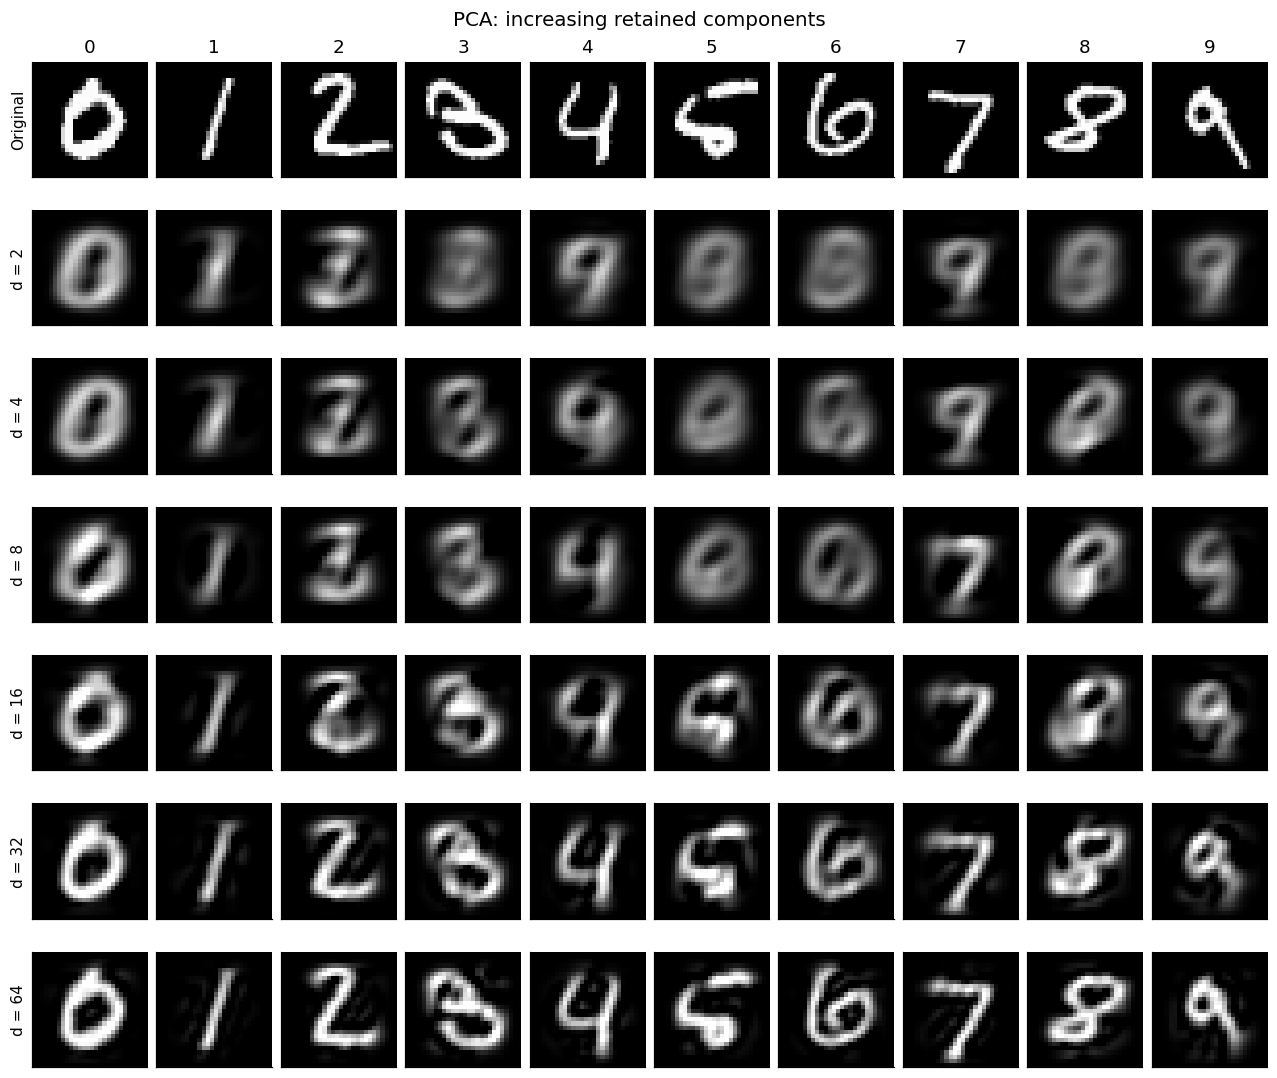

In [16]:
example_indices = np.array([np.flatnonzero(y_test == digit)[0] for digit in range(10)])
example_X = X_test[example_indices]
example_x = torch.from_numpy(example_X).reshape(-1, 1, 28, 28).to(device)

ae_examples = {}
for d in LATENT_DIMS:
    model = ae_models[d].to(device)
    model.eval()
    with torch.inference_mode():
        ae_examples[d] = model(example_x).cpu().numpy()
    model.cpu()

pca_examples = {d: pca_reconstruct(example_X, d) for d in LATENT_DIMS}
labels = ['Original'] + [f'd = {d}' for d in LATENT_DIMS]
image_rows([example_X] + [ae_examples[d] for d in LATENT_DIMS], labels, list(range(10)),
           'Autoencoder: increasing latent dimension | ' + RUN_LABEL)
image_rows([example_X] + [pca_examples[d] for d in LATENT_DIMS], labels, list(range(10)),
           'PCA: increasing retained components')


### Compare methods directly at one dimension

Change `COMPARE_DIM` to any value already fitted above and rerun this cell. The reconstructions
are deterministic; rerunning this display does not train the models again.


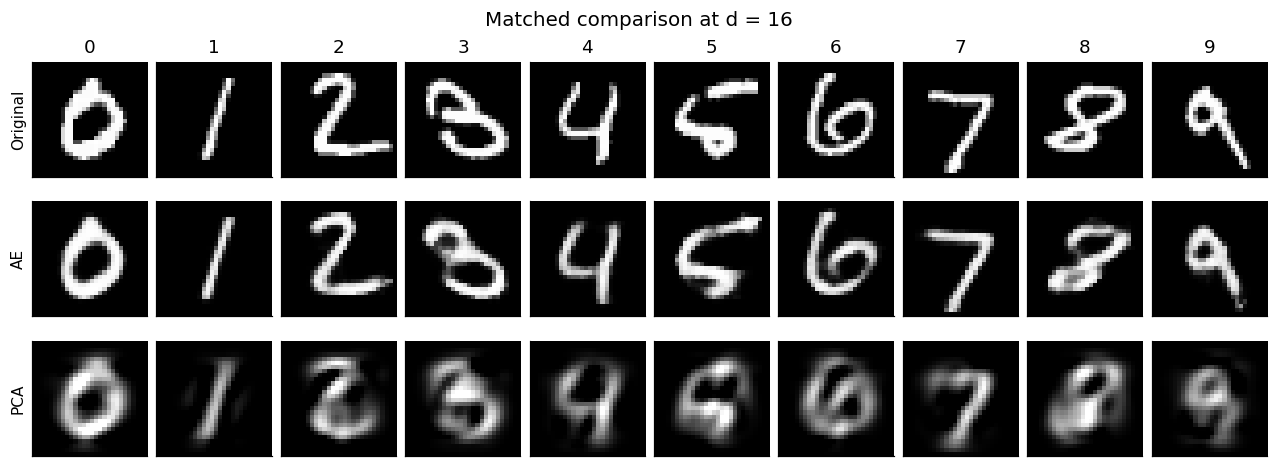

In [17]:
COMPARE_DIM = 16 if 16 in LATENT_DIMS else LATENT_DIMS[-1]
assert COMPARE_DIM in LATENT_DIMS
image_rows([example_X, ae_examples[COMPARE_DIM], pca_examples[COMPARE_DIM]],
           ['Original', 'AE', 'PCA'], list(range(10)),
           f'Matched comparison at d = {COMPARE_DIM}')


## 5. A two-dimensional view of the encoded test images

If $d=2$ was fitted, show both latent coordinates directly. The same test images and digit colors
appear in both panels. Class labels were not used in fitting. A visibly separated embedding and
a low reconstruction error are different properties; neither guarantees the other.

For $d>2$, two coordinates would show only a projection of the code. We therefore reserve this
figure for the actual two-dimensional models.


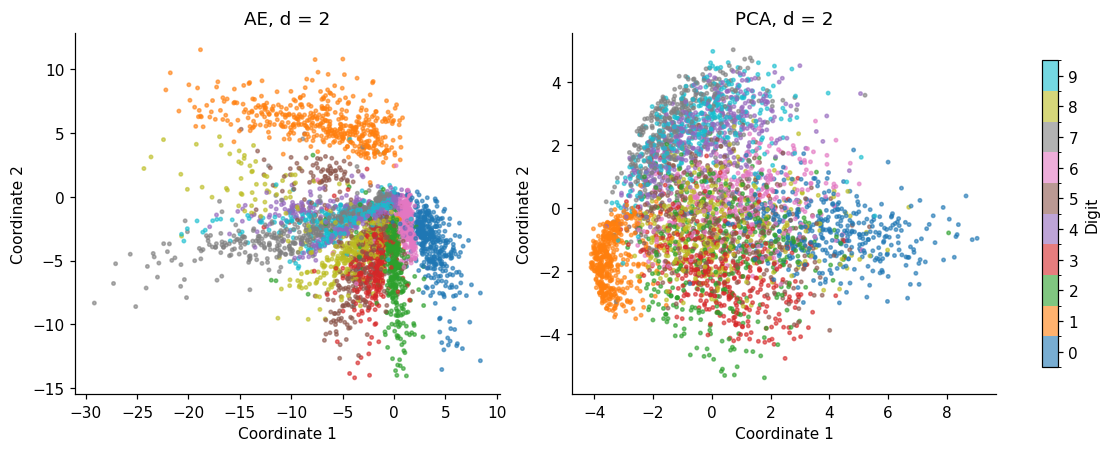

In [18]:
@torch.inference_mode()
def encode_dataset(model, loader):
    model.eval()
    return np.concatenate([model.encoder(x.to(device)).cpu().numpy() for x, _ in loader])


if 2 in LATENT_DIMS:
    model = ae_models[2].to(device)
    Z_test_ae = encode_dataset(model, test_loader)
    model.cpu()
    Z_test_pca = pca_encode(X_test, 2)
    indices = np.random.default_rng(SEED).choice(len(X_test), size=4000, replace=False)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
    cmap = plt.get_cmap('tab10', 10)
    norm = BoundaryNorm(np.arange(-0.5, 10.5), cmap.N)
    for ax, z, title in zip(axes, [Z_test_ae, Z_test_pca], ['AE, d = 2', 'PCA, d = 2']):
        points = ax.scatter(z[indices, 0], z[indices, 1], c=y_test[indices],
                            cmap=cmap, norm=norm, s=5, alpha=0.6, rasterized=True)
        ax.set(title=title, xlabel='Coordinate 1', ylabel='Coordinate 2')
    fig.colorbar(points, ax=axes, ticks=range(10), label='Digit', shrink=0.85)
    plt.show()
else:
    print('Include 2 in LATENT_DIMS to display both coordinates of a 2D code.')
